In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

1. 데이터 전처리
- length,weight 합치기
- 라벨값 생성
2. 훈련데이터,테스트데이터 분리
3. 표준점수 적용
4. 데이터학습
5. 데이터예측
6. 정확도
7. 그래프 출력

In [2]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어 - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]
length = bream_length + smelt_length
weight = bream_weight + smelt_weight

In [3]:
# 합치기, 라벨값
data= np.column_stack((length,weight))
label = [1]*35+[0]*14

In [4]:
# 정규화가 안된 형태 - 훈련데이터,테스트데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label)

정규화작업 - 표준점수 적용

In [5]:
# 데이터 전처리
# 표준점수 고려해야 함.
# 표준점수 = (특성값 - 산술평균) / 표준편차
# mean = np.mean(data,axis=0) # 행의 기준으로 산술평균
# std = np.std(data,axis=0)   # 행의 기준으로 표준편차
# train_scaled = (data-mean)/std
# new_data = ([25,120]-mean)/std

In [6]:
# 규제,정규화작업
ss = StandardScaler()
# 
ss.fit(train_data)   # 정규화 데이터로 훈련시켜줌.
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)
new_scaled = ss.transform([[25,120]])
new_scaled

array([[-0.28937323, -1.09416325]])

In [7]:
# 데이터 학습
clf = KNeighborsClassifier()
clf.fit(train_scaled,train_label)
# 데이터 예측
result = clf.predict(test_scaled)
# 정확도
score = clf.score(test_scaled,test_label)
print("예측 : ",score)

# kneighbors 알고리즘 사용시
distances,indexes = clf.kneighbors(new_scaled)
indexes

예측 :  1.0


array([[24, 25, 29, 28, 13]])

In [8]:
new_scaled

array([[-0.28937323, -1.09416325]])

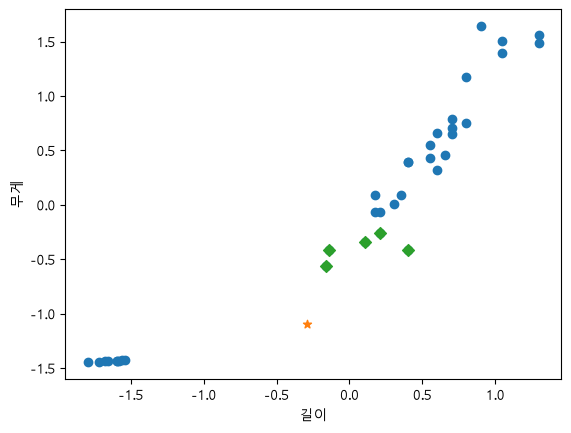

In [9]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_scaled[:,0],new_scaled[:,1],marker='*')
plt.scatter(train_scaled[indexes,0],train_scaled[indexes,1],marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [5]:
# 표준점수를 적용해서 전체 데이터와 [25,120] 를 scatter 그래프에 출력하시오.